# 34-과제. 공공데이터로 그래프 만들기 — 식약처 레시피 그래프

> 제출자: 김병주 · 제출 파일: `김병주_34과제.ipynb` + `COOKRCP01.csv`(두 파일을 같은 폴더에 둡니다)

| 항목 | 내용 |
|---|---|
| 데이터 이름 | 식품의약품안전처 「조리식품의 레시피 DB」 — 식품안전나라 Open API 서비스 ID `COOKRCP01` |
| 받은 곳(주소) | 식품안전나라 Open API: <https://www.foodsafetykorea.go.kr/api/openApiInfo.do?menu_grp=MENU_GRP31&menu_no=661&show_cnt=10&start_idx=1&svc_no=COOKRCP01> (CSV 다운로드·OpenAPI 제공, 파일 요청 형식 `http://openapi.foodsafetykorea.go.kr/api/{인증키}/COOKRCP01/file`) |
| 공공데이터포털 | 「식품의약품안전처_조리식품의 레시피 DB」 <https://www.data.go.kr/data/15060073/openapi.do> (LINK형 — 식품안전나라로 연결) |
| 이용 조건 | 공공데이터포털 표기 **이용허락범위 제한 없음**, 비용 무료 (2026-10-24 확인) |
| 서비스 정보 | 제공기관 식품의약품안전처, 최초 개방 2017-12-19, 최종 수정 2021-08-03, 업데이트 주기 상시 (식품안전나라 표기, 2026-10-24 확인) |
| 수집일 | **실제 최초 다운로드 일시: 확인 불가**(받은 날짜·경로 기록 없음). 확인 가능한 가장 이른 근거는 원본 `COOKRCP01.csv`의 **최초 Git 커밋 2026-10-21 16:02 KST**이며, 다운로드는 그 이전입니다. 이 날짜는 다운로드일이 아니라 "늦어도 이 날에는 받아 두었다"는 기준일입니다. 2026-10-22에 PostgreSQL `rcp_raw`에 등록(1단계 출력) |
| 원본 규모 | 레시피 1,156행 × 원본 55열 (`RCP_SEQ` 1,156개 유일) |
| 거른 조건 | 행은 거르지 않음. 재료 줄 가운데 표준 식재료 사전과 정확히 일치하지 않는 줄은 그래프에서 제외(3단계) |
| 제출 CSV | `COOKRCP01.csv`(노트북과 같은 폴더) — 받은 원본 그대로(1,739,442 bytes, UTF-8 BOM, SHA-256 `3f58fd2f…20305d3`) |

**제출 CSV에 대해**: 노트북과 같은 폴더의 `COOKRCP01.csv`가 받은 원본 파일입니다. 재료·조리 과정 칸 안의 줄바꿈이 `CRLF`(`\r\n`)이고,
프로젝트 PostgreSQL `recipe.rcp_raw`는 같은 값을 `LF`(`\n`)로 보관합니다. 1단계에서 칸 안 줄바꿈만 `\n`으로 맞춘 뒤 `rcp_raw`와 모든 칸이 같은지 확인합니다.

**DB 사용 원칙**
- 원본·정제 데이터: PostgreSQL `recipe` 스키마를 `READ ONLY` 트랜잭션으로만 읽습니다.
- 넣기(4단계)·정리(6단계): **별도 테스트 Neo4j**(`ASSIGNMENT_NEO4J_URI`)에만 씁니다. 배포된 Streamlit 앱이 쓰는 운영 AuraDB(`NEO4J_URI`)와 주소가 같거나 AuraDB 주소이면 실행을 멈춥니다.
- 답하기(5단계): 테스트 DB 결과를 운영 AuraDB의 **읽기 전용** 조회 결과와 대조합니다.
- 접속 정보·API 키는 저장소 루트 `.env`와 환경변수에서만 읽고 출력하지 않습니다.

**실행 조건과 한계 (채점 환경에서 다시 실행할 때)**
- 이 노트북은 과제 폴더의 프로젝트 코드(`recipe_recommender`·`common` 패키지, 적재·질문 `.cypher` 파일)를 불러 씁니다. 이 코드는 제출 파일에 넣지 않았으므로 **노트북과 CSV만으로는 0단계부터 실행되지 않습니다.**
- 다시 실행하려면 프로젝트 PostgreSQL(`recipe` 스키마, 읽기), 운영 AuraDB(읽기), 쓰기 검증용 별도 Neo4j가 필요합니다. 접속 정보는 저장소 루트 `.env`에서 읽습니다.
- 그래서 아래 셀에는 이 PC에서 실제로 실행한 결과를 남겨 두었습니다. 2026-10-24에 위에서부터 끝까지 실행한 결과이고, 원본 CSV로 바꾼 1단계 셀만 2026-10-25에 다시 실행했습니다(PostgreSQL 읽기 전용, 1단계 이후 결과에는 영향 없음).
- 노트북의 숫자(레시피 1,156 · 식재료 275 · 관계 10,428 등)는 2026-10-24 시점 DB 기준이며, 데이터를 다시 적재하면 바뀔 수 있습니다.

### 온라인 시연 및 결과 확인

본 과제에서 구성한 Neo4j 그래프를 활용한 레시피 추천 및 관계 탐색 프로그램을 Streamlit으로 배포했습니다.

**[레시피 GraphRAG — Streamlit 실행하기](https://graph-rag-2mxd3ncwawqtganwvqxykr.streamlit.app/)**

- 모드 A: 냉장고 식재료 기반 레시피 추천
- 모드 B: Q1~Q5 그래프 관계 탐색(1·2·3-hop)
- 노트북에 저장된 Cypher 조회 결과와 별도로 실제 애플리케이션을 체험할 수 있습니다.

> 이 링크는 구현한 프로그램의 **온라인 시연 및 결과 확인을 위한 참고 자료**입니다. 노트북 전체의 독립 재실행을 보장하지 않으며, 노트북 재실행 조건은 위 "실행 조건과 한계"를 따릅니다.

### 과제 노션 정리

[과제_공공데이터로-그래프-만들기_금요일까지 — 단계별 모델·검증·질문 결과 정리](https://app.notion.com/p/404c53ef97048161a26cdb582f284c1c?pvs=204)

위 노션은 노트북 내용의 복습용 정리 페이지입니다. 공유 권한은 별도로 설정해야 하며, 원본 과제의 실행 결과는 이 노트북을 기준으로 확인합니다.


## 0. 준비
- 과제 폴더의 `recipe_recommender` 패키지(실제 서비스 코드)를 그대로 불러 씁니다. 적재·질문 Cypher는 서비스가 쓰는 `.cypher` 파일의 원문입니다.
- 필요한 환경변수: `DB_URL`(PostgreSQL), `NEO4J_URI`·`NEO4J_USERNAME`·`NEO4J_PASSWORD`·`NEO4J_DATABASE`(운영 AuraDB, 읽기),
  `ASSIGNMENT_NEO4J_URI`·`ASSIGNMENT_NEO4J_USERNAME`·`ASSIGNMENT_NEO4J_PASSWORD`(테스트 Neo4j, 쓰기).

In [1]:
import os
import sys
from pathlib import Path

import pandas as pd

# 과제 폴더(recipe_recommender 패키지가 있는 곳)를 import 경로에 올린다. 노트북이 어디서 열려도 위로 올라가며 찾는다.
TASK_DIR = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "recipe_recommender").is_dir())
if str(TASK_DIR) not in sys.path:
    sys.path.insert(0, str(TASK_DIR))

from recipe_recommender.config import load_project_environment, prepare_common_imports

load_project_environment()          # 저장소 루트 .env — 값은 출력하지 않는다
prepare_common_imports()
pd.set_option("display.max_colwidth", 70)
pd.set_option("display.width", 200)
print("과제 폴더:", TASK_DIR.name)
print("환경변수 준비:", {name: bool(os.getenv(name)) for name in
      ("DB_URL", "NEO4J_URI", "ASSIGNMENT_NEO4J_URI", "ASSIGNMENT_NEO4J_PASSWORD")})

과제 폴더: 과제_공공데이터로-그래프-만들기_금요일까지
환경변수 준비: {'DB_URL': True, 'NEO4J_URI': True, 'ASSIGNMENT_NEO4J_URI': True, 'ASSIGNMENT_NEO4J_PASSWORD': True}


In [2]:
from common.database_manager import DatabaseManager


def pg_frames(queries: dict) -> dict:
    """PostgreSQL recipe 스키마를 한 READ ONLY 트랜잭션에서 읽어 DataFrame 묶음으로 돌려준다(쓰기 없음)."""
    manager = DatabaseManager()
    try:
        with manager.connect(camel_case_keys=False) as conn:
            conn.execute("BEGIN TRANSACTION ISOLATION LEVEL REPEATABLE READ READ ONLY")
            try:
                return {name: pd.DataFrame([dict(row) for row in conn.execute(sql).fetchall()])
                        for name, sql in queries.items()}
            finally:
                conn.rollback()          # 읽기 트랜잭션 종료
    finally:
        manager.close()

## 1단계. 표 보기
제출 CSV(받은 원본 `COOKRCP01.csv`, 노트북과 같은 폴더, 55열)를 읽습니다. 칸 안 줄바꿈(`\r\n`)만 `\n`으로 맞춥니다. 3단계에서 PostgreSQL 정제 표와 이어 붙이므로, CSV가 PostgreSQL `recipe.rcp_raw`와 같은지도 먼저 확인합니다.

In [3]:
CSV_PATH = Path("COOKRCP01.csv")       # 받은 원본 그대로 — 노트북과 같은 폴더(Jupyter 작업 폴더 = 노트북 폴더)
source = pd.read_csv(CSV_PATH, dtype=str, keep_default_na=False, encoding="utf-8-sig")   # 빈칸은 "" 그대로 읽는다
print("CSV:", CSV_PATH.name, "/ 줄 수:", len(source), "/ 열 수:", source.shape[1])
crlf = source.apply(lambda col: col.str.contains("\r\n", regex=False)).to_numpy().sum()
source = source.apply(lambda col: col.str.replace("\r\n", "\n", regex=False))   # 칸 안 줄바꿈을 rcp_raw와 같은 \n으로
print("칸 안 줄바꿈 CRLF → LF로 맞춘 칸 수:", crlf)

frames = pg_frames({
    "raw": "SELECT * FROM recipe.rcp_raw ORDER BY rcp_raw_seq",
    "batch": "SELECT rcp_raw_id, count(*) AS rows, min(create_date)::text AS registered_at FROM recipe.rcp_raw GROUP BY rcp_raw_id",
})
raw_all = frames["raw"]                                     # 3단계에서 행 순번(rcp_raw_seq)으로 이어 붙일 때 쓴다
db_values = raw_all[[c.lower() for c in source.columns]].fillna("").to_numpy()
print("CSV = PostgreSQL rcp_raw (모든 칸, 같은 행 순서):", (source.to_numpy() == db_values).all())
raw = source.rename(columns=str.lower).replace({"": None})  # 이하 분석은 CSV 기준, 빈 문자열은 빈칸
print("줄 수:", len(raw), "/ 원본 열 수:", raw.shape[1], "/ RCP_SEQ 종류:", raw["rcp_seq"].nunique())
print("PostgreSQL 등록 회차:", frames["batch"].to_dict("records"))
print("요리 분류(RCP_PAT2):", raw["rcp_pat2"].value_counts().to_dict())
print("조리 방법(RCP_WAY2):", raw["rcp_way2"].value_counts().to_dict())
manual = [f"manual{n:02d}" for n in range(1, 21)]
other = [c for c in raw.columns if c not in manual and not c.startswith("manual_img")]
blank = raw[other].isna().sum()
print("빈칸(조리 과정 열 제외):", blank[blank > 0].to_dict())
print("조리 과정 열(MANUAL01~20)별 채워진 칸:", raw[manual].notna().sum().to_dict())
raw[["rcp_seq", "rcp_nm", "rcp_pat2", "rcp_way2", "rcp_parts_dtls", "manual01"]].head()

CSV: COOKRCP01.csv / 줄 수: 1156 / 열 수: 55
칸 안 줄바꿈 CRLF → LF로 맞춘 칸 수: 3276


CSV = PostgreSQL rcp_raw (모든 칸, 같은 행 순서): True
줄 수: 1156 / 원본 열 수: 55 / RCP_SEQ 종류: 1156
PostgreSQL 등록 회차: [{'rcp_raw_id': '20261022_000001', 'rows': 1156, 'registered_at': '2026-10-22 06:26:26.649326+00'}]
요리 분류(RCP_PAT2): {'반찬': 574, '일품': 181, '후식': 142, '밥': 119, '국&찌개': 103, '기타': 37}
조리 방법(RCP_WAY2): {'끓이기': 326, '기타': 310, '굽기': 259, '볶기': 108, '찌기': 82, '튀기기': 71}
빈칸(조리 과정 열 제외): {'info_wgt': 871, 'hash_tag': 799, 'att_file_no_main': 2, 'att_file_no_mk': 1, 'rcp_parts_dtls': 3, 'rcp_na_tip': 54}
조리 과정 열(MANUAL01~20)별 채워진 칸: {'manual01': 1153, 'manual02': 1154, 'manual03': 1155, 'manual04': 1105, 'manual05': 1102, 'manual06': 1048, 'manual07': 0, 'manual08': 0, 'manual09': 0, 'manual10': 0, 'manual11': 0, 'manual12': 0, 'manual13': 0, 'manual14': 0, 'manual15': 0, 'manual16': 0, 'manual17': 0, 'manual18': 0, 'manual19': 0, 'manual20': 0}


,rcp_seq,rcp_nm,rcp_pat2,rcp_way2,rcp_parts_dtls,manual01
0,28,새우 두부 계란찜,반찬,찌기,"새우두부계란찜\n연두부 75g(3/4모), 칵테일새우 20g(5마리), 달걀 30g(1/2개), 생크림 13g(1큰술)...",1. 손질된 새우를 끓는 물에 데쳐 건진다.a
1,29,부추 콩가루 찜,반찬,찌기,"[1인분]조선부추 50g, 날콩가루 7g(1⅓작은술)\n·양념장 : 저염간장 3g(2/3작은술), 다진 대파 5g(1작...","1. 부추는 깨끗이 씻어 물기를 제거하고, 5cm 길이로 썰고 부추에 날콩가루를 넣고 고루 섞이도록 버무린다."
2,31,방울토마토 소박이,반찬,기타,"●방울토마토 소박이 : \n방울토마토 150g(5개), 양파 10g(3×1cm), 부추 10g(5줄기)\n●양념장 : ...",1. 물기를 빼고 2cm 정도의 크기로 썰은 부추와 양파를 양념장에 섞어 양념속을 만든다.
3,32,순두부 사과 소스 오이무침,반찬,기타,"●오이무침 :\n오이 70g(1/3개), 다진 땅콩 10g(1큰술)\n●순두부사과 소스 : \n순두부 40g(1/8봉지...","1. 사과, 순두부를 믹서에 넣고 곱게 갈아 소스를 만든다."
4,33,사과 새우 북엇국,국&찌개,끓이기,"북엇국\n북어채 25g(15개), 새우 10g(3마리), 사과 30g(1/5개), 양파 40g(1/4개),\n표고버섯 ...",None


- **한 줄 = 레시피 하나**입니다. `RCP_SEQ`(식약처 레시피 번호)가 줄 수와 같아 레시피를 하나로 가리킵니다.
- 재료는 `RCP_PARTS_DTLS` **한 칸에 여러 재료가 글로** 들어 있습니다(수량·단위·소제목 포함). 펴서 식재료 노드로 만들어야 합니다.
- 조리 과정은 `MANUAL01~20`(설명)과 `MANUAL_IMG01~20`(사진)으로 **옆으로 나열**되어 있고 레시피마다 채워진 칸 수가 다릅니다.
- 요리 분류(`RCP_PAT2`)는 6개 값이 여러 줄에 반복됩니다 → 노드 후보입니다.

#### 그림 1. PostgreSQL 관계형 DB ERD (`recipe` 스키마)

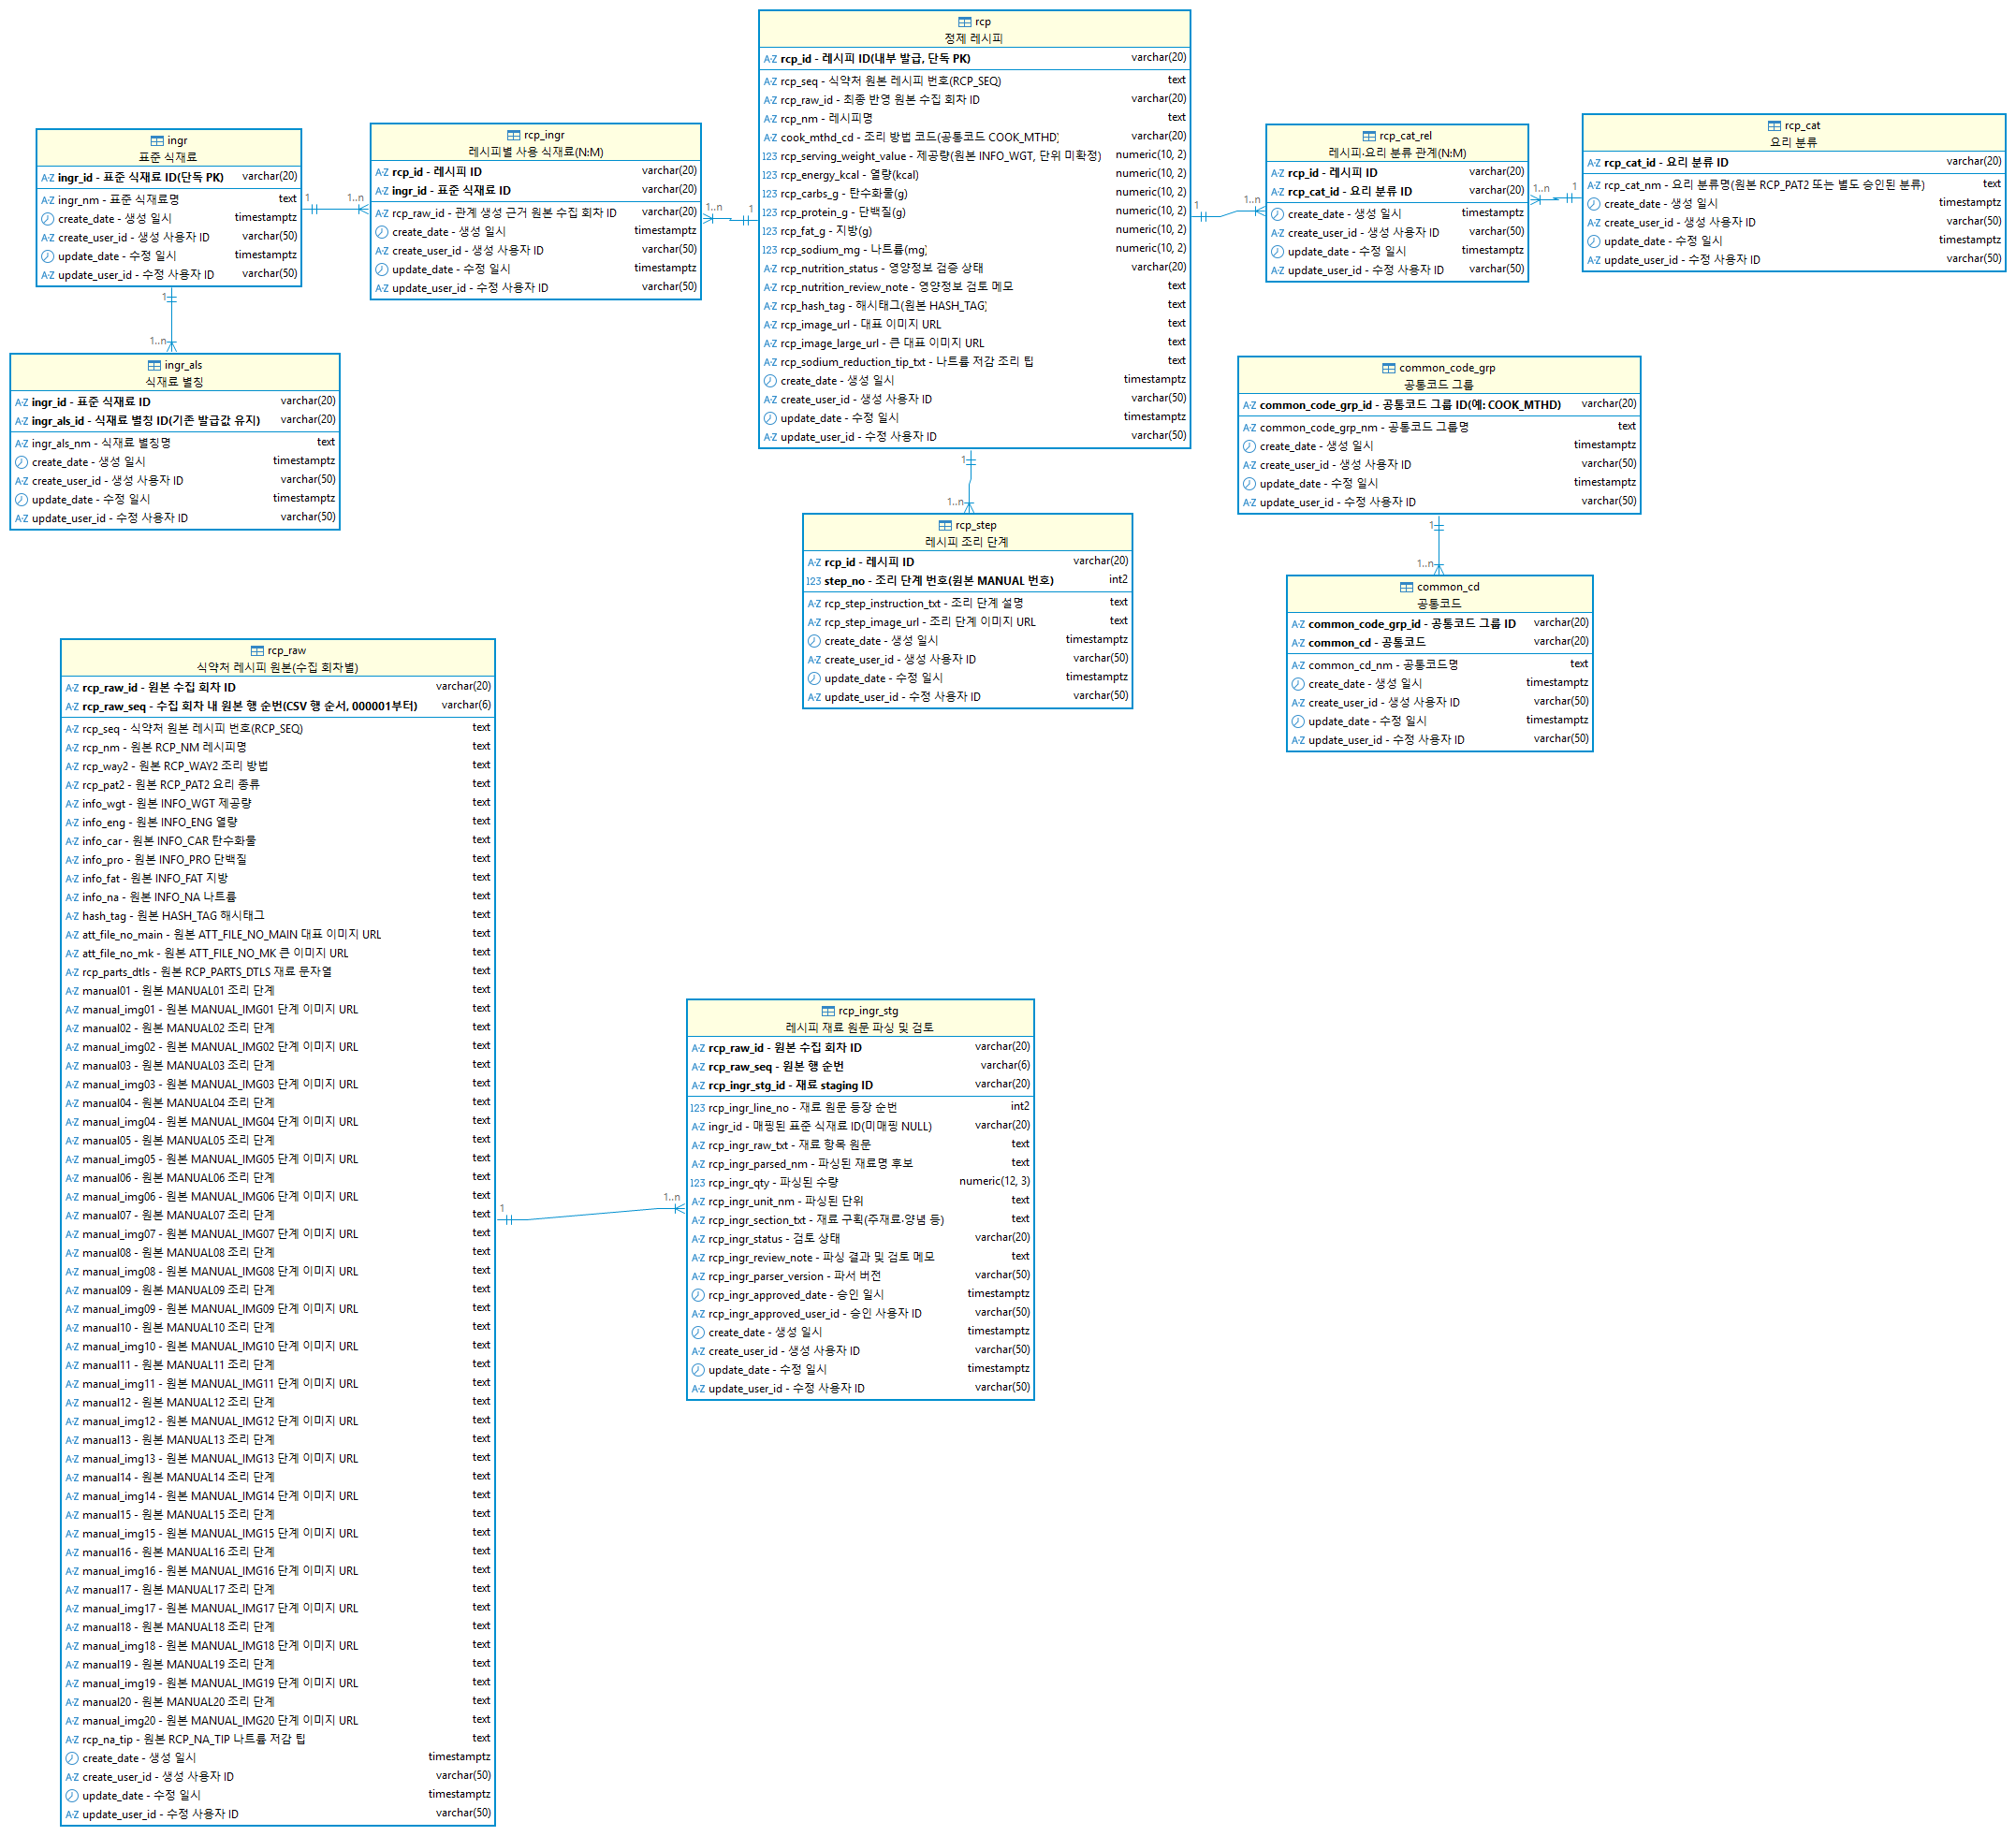

- 위 CSV 55열은 `rcp_raw`(수집 회차별 원본, 왼쪽 아래)에 문자열 그대로 보관됩니다. 1단계의 "CSV = rcp_raw" 대조가 이 표와의 비교입니다.
- 정제 테이블: 레시피 `rcp` · 표준 식재료 `ingr`(+ 별칭 `ingr_als`) · 요리 분류 `rcp_cat` · 조리 단계 `rcp_step`(키 `rcp_id` + `step_no`).
- 다대다 관계 테이블: `rcp_ingr`(레시피 ↔ 식재료), `rcp_cat_rel`(레시피 ↔ 분류). 재료 문자열을 줄로 편 결과와 검토 상태는 `rcp_ingr_stg`에 있습니다.
- 3단계는 이 테이블들을 읽기 전용으로 읽어 전후 줄 수를 확인하고, 4단계는 같은 테이블에서 그래프 노드·관계를 만듭니다.

**ERD와 Neo4j 구조도(그림 2)의 역할**
- **ERD(보조 설계 자료)**: 원천을 저장하고 정합성을 지키는 구조입니다. 원본 보관(`rcp_raw`), 재료 파싱 검토(`rcp_ingr_stg`), 공통코드, PK·FK를 다룹니다.
- **Neo4j 구조도**: 질문에 답하려고 관계를 따라가는 탐색 모델입니다. 2단계 질문의 hop이 이 구조 위에서 정해집니다.
- **연결**: 엔터티 테이블은 노드로, 관계 테이블과 FK는 관계로 옮깁니다.

| PostgreSQL (ERD) | Neo4j (그림 2) |
|---|---|
| `rcp` (+ `common_cd`의 조리 방법명) | `rcp` 노드 (`cook_mthd_nm` 속성) |
| `ingr` + `ingr_als` | `ingr` 노드 (별칭은 `alias_names` 목록 속성) |
| `rcp_cat` | `rcp_cat` 노드 |
| `rcp_step` (FK `rcp_id`) | `rcp_step` 노드 + `RCP_HAS_STEP` 관계 |
| `rcp_ingr` (N:M) | `RCP_USES` 관계 |
| `rcp_cat_rel` (N:M) | `RCP_IN_RECIPE_CATEGORY` 관계 |
| `rcp_raw` · `rcp_ingr_stg` · `common_code_grp` | 그래프에 넣지 않음 (적재 전 검증에만 사용) |


## 2단계. 질문 먼저
| 번호 | Hop | 질문 |
|---|---|---|
| 질문 1 | 1 | 두부를 사용하는 레시피는 무엇인가? |
| 질문 2 | 2 | 된장 두부찌개와 공통 재료를 사용하는 다른 레시피는 무엇인가? |
| 질문 3 | 3 | 된장 두부찌개와 공통 재료(3개 이상)를 사용하는 다른 레시피들은 어떤 요리 분류에 속하는가? |
| 질문 4 | 2 | 반찬으로 분류된 레시피에서 사용하는 식재료는 무엇인가? |
| 질문 5 | 1 | 된장 두부찌개의 조리 단계와 순서는 무엇인가? |

Hop은 Cypher 패턴에서 **관계를 건너가는 횟수**입니다. 질문 2·3·4가 관계를 두 번 이상 건너갑니다.

| 질문 속 말 | 종류 | 그래프에서 |
|---|---|---|
| 레시피 · 식재료 · 요리 분류 · 조리 단계 | 명사(대상) | 노드 `rcp` · `ingr` · `rcp_cat` · `rcp_step` |
| ~를 사용한다 · ~로 분류된다 · ~단계를 가진다 | 동사(관계) | 관계 `RCP_USES` · `RCP_IN_RECIPE_CATEGORY` · `RCP_HAS_STEP` |
| 레시피 이름 · 원본 번호 · 사진 | 대상의 성질 | `rcp` 속성 `rcp_nm` · `rcp_seq` · `rcp_image_url` |
| 식재료 이름 · 별칭(계란 → 달걀) | 대상의 성질 | `ingr` 속성 `ingr_nm` · `alias_names` (+ 정규화 `_norm`) |
| 단계 번호 · 설명 · 단계 사진 | 대상의 성질 | `rcp_step` 속성 `step_no` · `rcp_step_instruction_txt` · `rcp_step_image_url` |

```mermaid
flowchart LR
    R["rcp<br/>rcp_id, rcp_seq, rcp_nm"]
    I["ingr<br/>ingr_id, ingr_nm, alias_names"]
    C["rcp_cat<br/>rcp_cat_id, rcp_cat_nm"]
    S["rcp_step<br/>(rcp_id, step_no), 설명, 사진"]
    R -- "RCP_USES" --> I
    R -- "RCP_IN_RECIPE_CATEGORY" --> C
    R -- "RCP_HAS_STEP" --> S
```

- 라벨 이름은 프로젝트 PostgreSQL 테이블 이름과 같습니다. 수업 예시 라벨(`Drug` 등)과 섞이지 않습니다.
- 열량·영양 정보·해시태그·나트륨 팁은 다섯 질문에 나오지 않아 그래프 질문에 쓰지 않습니다.

#### 그림 2. Neo4j 그래프 구조도 (노드 속성 · 키 제약)

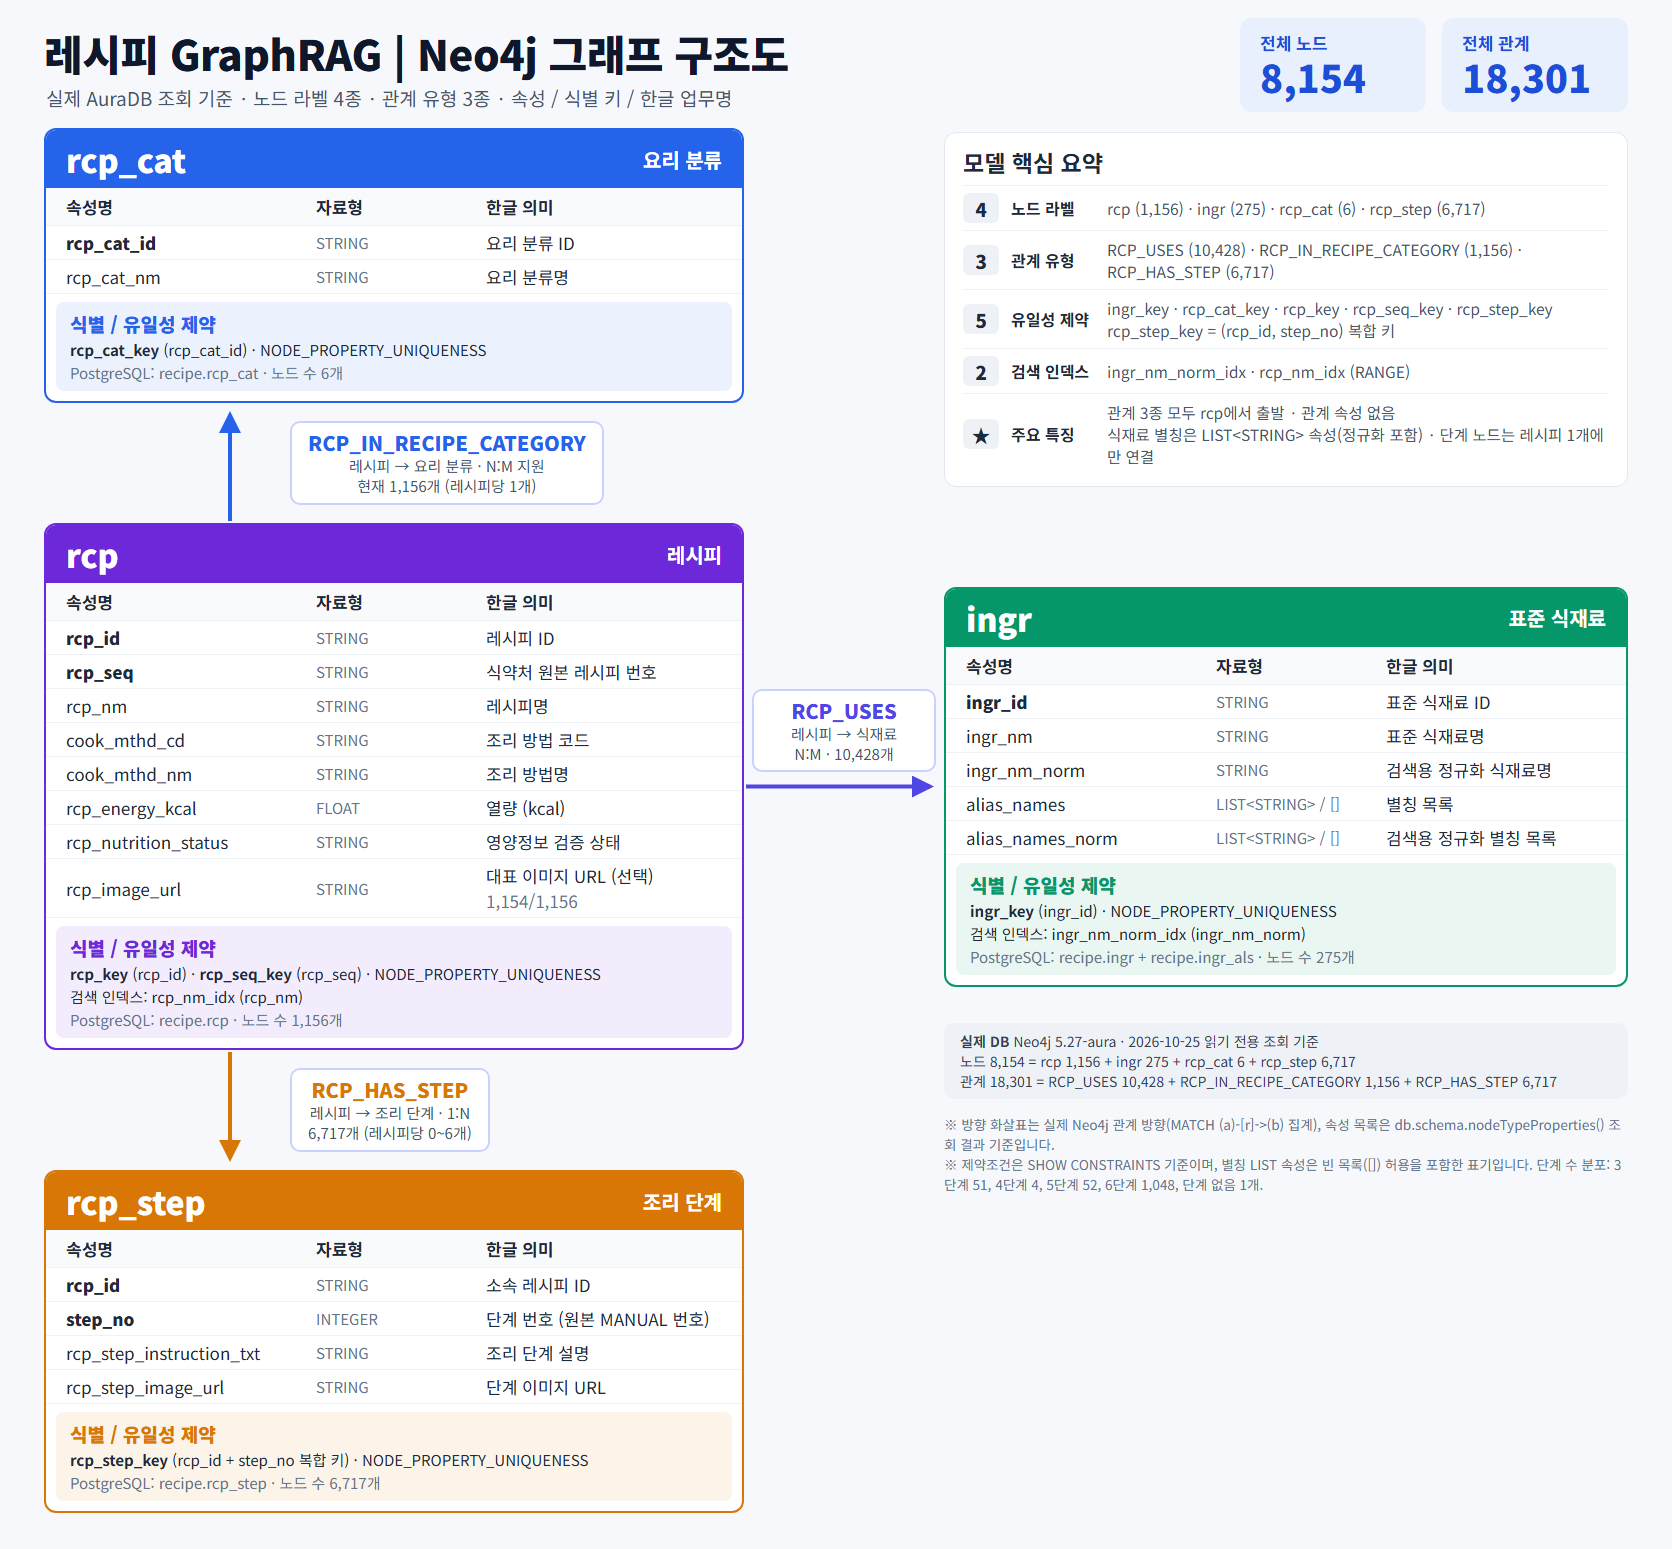

- 노드 4종 `rcp`(레시피) · `ingr`(표준 식재료) · `rcp_cat`(요리 분류) · `rcp_step`(조리 단계)의 속성 · 자료형 · 유일성 제약과, `rcp`에서 나가는 관계 3종 `RCP_USES` · `RCP_IN_RECIPE_CATEGORY` · `RCP_HAS_STEP`의 방향을 보여 줍니다(위 Mermaid 그림과 같은 모델).
- 조리 단계 키는 (`rcp_id`, `step_no`) 복합 키입니다. 단계 번호는 레시피마다 1부터 다시 시작하기 때문입니다.
- 노드 8,154개 · 관계 18,301개는 4단계 넣기 출력과 같은 숫자입니다(2026-10-25 운영 AuraDB 읽기 전용 조회로 그린 그림).


## 3단계. 질문에 맞게 다듬기
프로젝트 등록 파이프라인(`setup/register_recipe_csv.py`)이 원본을 다듬어 PostgreSQL 목표 테이블에 넣어 두었습니다.
여기서는 그 결과를 읽기 전용으로 불러 **처리마다 전후 줄 수**를 확인하고, pandas로 다시 계산해 맞는지 봅니다.

In [4]:
f = pg_frames({
    "rcp": "SELECT rcp_id, rcp_seq, rcp_nm, rcp_image_url FROM recipe.rcp",
    "cat": "SELECT rcp_cat_id, rcp_cat_nm FROM recipe.rcp_cat",
    "cat_rel": "SELECT rcp_id, rcp_cat_id FROM recipe.rcp_cat_rel",
    "ingr": "SELECT ingr_id, ingr_nm FROM recipe.ingr",
    "als": "SELECT ingr_id, ingr_als_nm FROM recipe.ingr_als",
    "stg": "SELECT rcp_raw_seq, rcp_ingr_line_no, ingr_id, rcp_ingr_raw_txt, rcp_ingr_parsed_nm, rcp_ingr_status "
           "FROM recipe.rcp_ingr_stg",
    "uses": "SELECT rcp_id, ingr_id FROM recipe.rcp_ingr",
    "steps": "SELECT rcp_id, step_no, rcp_step_instruction_txt, rcp_step_image_url FROM recipe.rcp_step",
})
print("레시피:", len(raw), "줄 →", len(f["rcp"]), "개 (거른 줄 없음)")
print("요리 분류:", raw["rcp_pat2"].nunique(), "종 →", len(f["cat"]), "노드 / 레시피-분류 관계", len(f["cat_rel"]))

레시피: 1156 줄 → 1156 개 (거른 줄 없음)
요리 분류: 6 종 → 6 노드 / 레시피-분류 관계 1156


**재료 펴기**: `RCP_PARTS_DTLS` 한 칸을 재료 줄로 나눈 뒤(수량·단위·소제목 분리), 줄의 재료 이름이
표준 식재료 사전(`data/ingr_seed.csv`, 표준명 + 별칭)과 **정확히 일치할 때만** 자동 승인합니다.
일치하지 않는 줄은 `PENDING_REVIEW`로 남기고 그래프에 넣지 않습니다(추측해서 붙이지 않기).

In [5]:
stg = f["stg"]
print("재료 칸(레시피 수):", raw["rcp_parts_dtls"].notna().sum())
print("재료 줄로 편 뒤:", len(stg))
print("상태별 줄 수:", stg["rcp_ingr_status"].value_counts().to_dict())
approved = stg[stg["rcp_ingr_status"] == "AUTO_APPROVED"]
# 재료 줄 → 원본 행 순번 → 레시피 번호 → 레시피 ID로 이어 붙인다
seq_by_raw = raw_all.set_index("rcp_raw_seq")["rcp_seq"]
rcp_by_seq = f["rcp"].set_index("rcp_seq")["rcp_id"]
pairs = approved.assign(rcp_id=approved["rcp_raw_seq"].map(seq_by_raw).map(rcp_by_seq))[["rcp_id", "ingr_id"]]
dedup = pairs.drop_duplicates()
print("승인된 재료 줄:", len(pairs), "→ 레시피 × 식재료 중복 제거:", len(dedup))
print("PostgreSQL rcp_ingr와 같은가:",
      set(map(tuple, dedup.values)) == set(map(tuple, f["uses"][["rcp_id", "ingr_id"]].values)))
print("식재료 노드:", len(f["ingr"]), "/ 별칭:", len(f["als"]),
      "/ 재료가 하나도 연결되지 않은 레시피:", len(set(f["rcp"]["rcp_id"]) - set(dedup["rcp_id"])))
stg[stg["rcp_ingr_status"] == "PENDING_REVIEW"][["rcp_ingr_raw_txt", "rcp_ingr_parsed_nm"]].head(5)

재료 칸(레시피 수): 1153
재료 줄로 편 뒤: 13080
상태별 줄 수: {'AUTO_APPROVED': 10611, 'PENDING_REVIEW': 2469}
승인된 재료 줄: 10611 → 레시피 × 식재료 중복 제거: 10428
PostgreSQL rcp_ingr와 같은가: True
식재료 노드: 275 / 별칭: 71 / 재료가 하나도 연결되지 않은 레시피: 8


,rcp_ingr_raw_txt,rcp_ingr_parsed_nm
0,조선부추 50g,조선부추
1,날콩가루 7g(1⅓작은술),날콩가루
2,요리당 2g(1/3작은술),요리당
3,다진 땅콩 10g(1큰술),다진 땅콩
4,북엇국,북엇국


**조리 과정 펴기**: 옆으로 나열된 `MANUAL01~20`을 세로로 펴서 (레시피, 원본 번호) 한 줄 = 단계 하나로 만듭니다.
설명이 빈 칸은 단계가 아닙니다. 원본 번호는 그대로 둡니다(중간 번호가 비어도 다시 매기지 않음).

In [6]:
long = raw.melt(id_vars=["rcp_seq"], value_vars=manual, var_name="col", value_name="text").dropna(subset=["text"])
long = long[long["text"].str.strip() != ""]
print("조리 과정 칸(1,156 × 20):", len(raw) * 20, "→ 설명이 있는 칸:", len(long))
print("PostgreSQL rcp_step:", len(f["steps"]), "/ 같은가:", len(long) == len(f["steps"]))
print("단계 사진이 없는 단계:", f["steps"]["rcp_step_image_url"].isna().sum(),
      "/ 대표 사진이 없는 레시피:", f["rcp"]["rcp_image_url"].isna().sum())
per_recipe = f["steps"].groupby("rcp_id").size()
print("레시피별 단계 수:", per_recipe.value_counts().sort_index().to_dict(),
      "/ 단계가 없는 레시피:", len(f["rcp"]) - per_recipe.size)

조리 과정 칸(1,156 × 20): 23120 → 설명이 있는 칸: 6717
PostgreSQL rcp_step: 6717 / 같은가: True
단계 사진이 없는 단계: 0 / 대표 사진이 없는 레시피: 2
레시피별 단계 수: {3: 51, 4: 4, 5: 52, 6: 1048} / 단계가 없는 레시피: 1


- 빈칸(사진 URL 등)은 Neo4j로 넘기기 전에 `None`이 되도록 적재 코드(`recipe_graph_source_repository.recipe_graph_row`, `_step_rows`)가 처리합니다. `None`을 `SET`하면 속성 자체가 생기지 않습니다.
- 열량(`numeric`)은 Neo4j 드라이버가 받는 `float`로 바꿉니다. 질문에는 쓰지 않습니다.

## 4단계. 넣기 (별도 테스트 Neo4j)
- 운영 AuraDB가 아닌 테스트 DB에만 씁니다. 아래 셀이 주소를 확인하고 아니면 멈춥니다.
- 적재는 서비스의 그래프 적재 Service(`RecipeGraphLoadService.apply`)를 그대로 씁니다. 순서: 사전 점검 → 제약 생성 → 노드 → 관계 → 조리 단계, 배치마다 `MERGE`.

In [7]:
from neo4j import GraphDatabase, RoutingControl

from recipe_recommender.recipe_graph_repository import RecipeGraphRepository
from recipe_recommender.setup.recipe_graph_load_service import RecipeGraphLoadService
from recipe_recommender.setup.recipe_graph_source_repository import RecipeGraphSourceRepository

TEST_URI = os.getenv("ASSIGNMENT_NEO4J_URI", "")
TEST_DB = os.getenv("ASSIGNMENT_NEO4J_DATABASE", "neo4j")
if not TEST_URI:
    raise RuntimeError("ASSIGNMENT_NEO4J_URI(쓰기 검증용 별도 Neo4j)를 설정하세요. 운영 AuraDB에는 쓰지 않습니다.")
if TEST_URI == os.getenv("NEO4J_URI") or "databases.neo4j.io" in TEST_URI:
    raise RuntimeError("테스트 DB 주소가 운영 AuraDB와 같거나 AuraDB 주소입니다. 쓰기를 멈춥니다.")
test_driver = GraphDatabase.driver(TEST_URI, auth=(os.getenv("ASSIGNMENT_NEO4J_USERNAME", "neo4j"),
                                                   os.environ["ASSIGNMENT_NEO4J_PASSWORD"]))
test_driver.verify_connectivity()
test_graph = RecipeGraphRepository(driver=test_driver, database=TEST_DB)     # DB 이름을 명시(운영 이름 사용 방지)
loader = RecipeGraphLoadService(RecipeGraphSourceRepository(), test_graph)
prepared = loader.prepare()            # PostgreSQL READ ONLY 스냅샷 → 키·부모·코드 검증 → 적재 입력
print("테스트 DB 연결 완료(주소는 출력하지 않음)")
print("적재 예정 건수:", prepared.expected_counts)

테스트 DB 연결 완료(주소는 출력하지 않음)
적재 예정 건수: {'rcp_cat': 6, 'ingr': 275, 'rcp': 1156, 'RCP_IN_RECIPE_CATEGORY': 1156, 'RCP_USES': 10428, 'rcp_step': 6717, 'RCP_HAS_STEP': 6717}


In [8]:
# 제약(키)과 적재 Cypher 원문 — 서비스의 .cypher 파일 그대로
for name in ("rcp_key", "ingr_key", "rcp_cat_key", "rcp_step_key"):
    print(test_graph.statement_text(f"recipe_graph_constraints.{name}"), "\n")
for name in ("load_recipes", "link_uses", "load_recipe_steps"):
    print(f"// {name}")
    print(test_graph.statement_text(f"recipe_graph_load.{name}"), "\n")

CREATE CONSTRAINT rcp_key IF NOT EXISTS
FOR (r:rcp) REQUIRE r.rcp_id IS UNIQUE; 

CREATE CONSTRAINT ingr_key IF NOT EXISTS
FOR (i:ingr) REQUIRE i.ingr_id IS UNIQUE; 

CREATE CONSTRAINT rcp_cat_key IF NOT EXISTS
FOR (c:rcp_cat) REQUIRE c.rcp_cat_id IS UNIQUE;

// 조리 단계 노드 키 = PostgreSQL recipe.rcp_step PK (rcp_id, step_no). step_no는 원본 MANUAL 번호(정수). 

CREATE CONSTRAINT rcp_step_key IF NOT EXISTS
FOR (s:rcp_step) REQUIRE (s.rcp_id, s.step_no) IS UNIQUE;

// 이름으로 찾는 질의용. 별칭 목록은 리스트라 이 RANGE 인덱스의 대상이 아님. 

// load_recipes
// recipe.rcp LEFT JOIN recipe.common_cd
//   ON common_code_grp_id = 'COOK_MTHD' AND common_cd = cook_mthd_cd.
// 코드 그룹 검증 실패 시 ETL에서 중단한다.
// $rows: [{rcp_id, rcp_seq, rcp_nm, cook_mthd_cd, cook_mthd_nm,
//          rcp_energy_kcal, rcp_nutrition_status, rcp_image_url}, ...]
UNWIND $rows AS row
MERGE (r:rcp {rcp_id: row.rcp_id})
SET r.rcp_seq = row.rcp_seq,
    r.rcp_nm = row.rcp_nm,
    r.cook_mthd_cd = row.cook_mthd_cd,
    r.cook_mthd_nm = row.cook_mthd_nm,
    r.rc

In [9]:
LABELS = ("rcp", "ingr", "rcp_cat", "rcp_step")


def count_all():
    """테스트 DB의 이 과제 라벨·관계 건수."""
    nodes = test_driver.execute_query(
        "MATCH (n) WHERE any(l IN labels(n) WHERE l IN $labels) RETURN labels(n)[0] AS name, count(*) AS n ORDER BY name",
        labels=list(LABELS), database_=TEST_DB).records
    rels = test_driver.execute_query(
        "MATCH (:rcp)-[r]->() RETURN type(r) AS name, count(*) AS n ORDER BY name", database_=TEST_DB).records
    return [(r["name"], r["n"]) for r in nodes] + [(r["name"], r["n"]) for r in rels]


print("넣기 전:", count_all())
first_report = loader.apply(prepared, batch_size=500)
first = count_all()
print("넣은 뒤:", first)
print("원천과 키·건수 대조:", {k: v for k, v in first_report["verified"].items() if not k.startswith("total")})

넣기 전: []


넣은 뒤: [('ingr', 275), ('rcp', 1156), ('rcp_cat', 6), ('rcp_step', 6717), ('RCP_HAS_STEP', 6717), ('RCP_IN_RECIPE_CATEGORY', 1156), ('RCP_USES', 10428)]
원천과 키·건수 대조: {'rcp_cat': 6, 'ingr': 275, 'rcp': 1156, 'rcp_step': 6717, 'RCP_IN_RECIPE_CATEGORY': 1156, 'RCP_USES': 10428, 'RCP_HAS_STEP': 6717, 'unlinked_recipes': 8, 'category_errors': 0, 'step_link_errors': 0}


In [10]:
second_report = loader.apply(prepared, batch_size=500)        # 같은 스냅샷을 한 번 더 넣는다
second = count_all()
print("두 번 넣어도 같은가:", first == second)
print("두 번째 넣기 전 → 뒤 전체 노드/관계:",
      (second_report["before_nodes"], second_report["before_relationships"]), "→", second)
print("제약:", [r["name"] for r in test_driver.execute_query(
    "SHOW CONSTRAINTS YIELD name RETURN name ORDER BY name", database_=TEST_DB).records])

두 번 넣어도 같은가: True
두 번째 넣기 전 → 뒤 전체 노드/관계: (8154, 18301) → [('ingr', 275), ('rcp', 1156), ('rcp_cat', 6), ('rcp_step', 6717), ('RCP_HAS_STEP', 6717), ('RCP_IN_RECIPE_CATEGORY', 1156), ('RCP_USES', 10428)]
제약: ['ingr_key', 'rcp_cat_key', 'rcp_key', 'rcp_seq_key', 'rcp_step_key']


- `MERGE`는 키로 찾고 없을 때만 만듭니다. 그래서 두 번 넣어도 노드·관계 수가 같습니다.
- 이 서비스는 `ON CREATE SET` 대신 `SET`을 씁니다. 원천(PostgreSQL)이 기준이라 다시 넣을 때 속성을 원천 값으로 맞추기 위해서입니다. 키는 `MERGE` 패턴에만 있으므로 중복이 생기지 않습니다.
- 조리 단계 키는 (레시피 ID, 단계 번호) 복합 키입니다. 단계 번호는 레시피마다 1부터 다시 시작하기 때문입니다.

## 5단계. 질문에 답하기
질문마다 서비스가 실제로 쓰는 Named Cypher 원문을 테스트 DB에서 실행합니다.
같은 Cypher를 운영 AuraDB에서 **읽기 전용**(`RoutingControl.READ`)으로도 실행해 결과가 같은지 확인합니다.

In [11]:
from recipe_recommender.neo4j_connection import create_neo4j_driver

prod_driver = create_neo4j_driver()          # 운영 AuraDB — 아래에서는 읽기만 한다
PROD_DB = os.getenv("NEO4J_DATABASE") or None


def comparable(rows: list[dict]) -> list[dict]:
    """대조용 사본: collect()로 모은 목록은 원소 순서가 실행마다 다를 수 있어 목록 안만 정렬한다."""
    return [{k: sorted(v) if isinstance(v, list) else v for k, v in row.items()} for row in rows]


def ask(statement: str, params: dict) -> pd.DataFrame:
    """Named Cypher를 테스트 DB에서 실행해 표로 돌려주고, 운영 AuraDB(읽기) 결과와 같은지 출력한다."""
    cypher = test_graph.statement_text(statement)
    test_rows = [r.data() for r in test_driver.execute_query(
        cypher, params, database_=TEST_DB, routing_=RoutingControl.READ).records]
    prod_rows = [r.data() for r in prod_driver.execute_query(
        cypher, params, database_=PROD_DB, routing_=RoutingControl.READ).records]
    print(f"{statement}: {len(test_rows)}행 / 운영 AuraDB와 같은가: {comparable(test_rows) == comparable(prod_rows)}")
    return pd.DataFrame(test_rows)


base = test_driver.execute_query("MATCH (r:rcp {rcp_seq: '137'}) RETURN r.rcp_id AS id, r.rcp_nm AS nm",
                                 database_=TEST_DB).records[0]
BASE_ID = base["id"]
print("기준 레시피:", base["nm"], "(원본 137번)")

기준 레시피: 된장 두부찌개 (원본 137번)


**질문 1. (1-hop)** 두부를 사용하는 레시피는 무엇인가?
경로 `(:ingr)<-[:RCP_USES]-(:rcp)` — 입력어는 표준명·별칭으로 식재료 노드를 찾는 **속성 비교**라 hop에 넣지 않습니다.

In [12]:
print(test_graph.statement_text("recipe_graph_queries.recipes_by_ingredient_term"))
q1 = ask("recipe_graph_queries.recipes_by_ingredient_term", {"term_norm": "두부"})
print("레시피 수:", q1["rcp_id"].nunique(), "/ 중복 행:", len(q1) - q1["rcp_id"].nunique())
q1_alias = ask("recipe_graph_queries.recipes_by_ingredient_term", {"term_norm": "계란"})
print("별칭 '계란' → 표준 식재료:", sorted(q1_alias["ingredient"].unique()), "/ 레시피 수:", len(q1_alias))
q1[["rcp_nm", "rcp_seq", "ingredient"]].head(10)

// '계란이 들어가는 레시피는?' — 입력어($term_norm, 양끝 공백 제거·소문자화)를 표준명 또는 별칭으로 해석한다.
// 별칭 '계란'은 표준 식재료 '달걀'로 매핑된다. 유사 이름(두부/연두부)은 합치지 않는다.
MATCH (i:ingr)
WHERE i.ingr_nm_norm = $term_norm OR $term_norm IN coalesce(i.alias_names_norm, [])
MATCH (r:rcp)-[:RCP_USES]->(i)
RETURN i.ingr_id AS ingr_id, i.ingr_nm AS ingredient,
       r.rcp_id AS rcp_id, r.rcp_seq AS rcp_seq, r.rcp_nm AS rcp_nm
ORDER BY r.rcp_nm, r.rcp_id;


recipe_graph_queries.recipes_by_ingredient_term: 110행 / 운영 AuraDB와 같은가: True
레시피 수: 110 / 중복 행: 0
recipe_graph_queries.recipes_by_ingredient_term: 186행 / 운영 AuraDB와 같은가: True
별칭 '계란' → 표준 식재료: ['달걀'] / 레시피 수: 186


,rcp_nm,rcp_seq,ingredient
0,가지 탕수육,3246,두부
1,가지볶음밥,215,두부
2,간편콩국수,342,두부
3,감자느타리버섯국,674,두부
4,겨자아욱쌈밥,615,두부
5,견과류들깨해장탕,264,두부
6,고구마순나물,3005,두부
7,곤약함박스테이크,296,두부
8,관자해장국,263,두부
9,굴 두부 국,875,두부


#### 질문 1에서 알 수 있는 인사이트
- 표준 식재료 `두부`를 쓰는 레시피는 **110개**이고, 같은 레시피가 두 번 나온 행은 없습니다(테스트 DB와 운영 AuraDB 결과 동일).
- `연두부`(12개)·`순두부`(11개)는 별도 식재료 노드라 이 결과에 들어가지 않습니다. 이름이 비슷한 재료를 합칠지는 데이터 정제 단계(식재료 사전)에서 정할 일이며, 이 프로젝트는 합치지 않았습니다.
- 별칭 `계란`은 노드 속성 `alias_names`로 표준 식재료 `달걀`을 찾아 **186개** 레시피를 돌려줍니다. 별칭 해석은 관계가 아니라 속성 비교라 hop에 넣지 않았습니다.

**질문 2. (2-hop)** 된장 두부찌개와 공통 재료를 사용하는 다른 레시피는 무엇인가?
경로 `(:rcp)-[:RCP_USES]->(:ingr)<-[:RCP_USES]-(:rcp)`. 공통 재료가 여러 개여도 `count(DISTINCT shared)`로 레시피를 한 번만 셉니다.

In [13]:
print(test_graph.statement_text("recipe_graph_queries.similar_recipes"))
q2 = ask("recipe_graph_queries.similar_recipes", {"rcp_id": BASE_ID})
print("중복 레시피:", len(q2) - q2["rcp_id"].nunique())
q2[["rcp_nm", "common_count", "common_ingredients", "jaccard"]].head(10)

// 공통 재료 수와 Jaccard = 교집합 / 합집합을 함께 제공한다.
MATCH (base:rcp {rcp_id: $rcp_id})
MATCH (base)-[:RCP_USES]->(shared:ingr)<-[:RCP_USES]-(candidate:rcp)
WHERE candidate <> base
WITH base, candidate, count(DISTINCT shared) AS common_count,
     collect(DISTINCT shared.ingr_nm) AS common_ingredients
WITH candidate, common_count, common_ingredients,
     size([(base)-[:RCP_USES]->() | 1]) AS base_total,
     size([(candidate)-[:RCP_USES]->() | 1]) AS candidate_total
RETURN candidate.rcp_id AS rcp_id,
       candidate.rcp_nm AS rcp_nm, common_count, common_ingredients,
       toFloat(common_count) / (base_total + candidate_total - common_count) AS jaccard
ORDER BY common_count DESC, jaccard DESC, rcp_id
LIMIT 20;


recipe_graph_queries.similar_recipes: 20행 / 운영 AuraDB와 같은가: True
중복 레시피: 0


,rcp_nm,common_count,common_ingredients,jaccard
0,부대된장찌개,5,"[청양고추, 두부, 홍고추, 김치, 대파]",0.357143
1,들깨된장육개장,5,"[청양고추, 된장, 고춧가루, 돼지고기, 대파]",0.294118
2,완자김치찌개,4,"[두부, 홍고추, 김치, 대파]",0.307692
3,배추된장국,4,"[청양고추, 된장, 두부, 대파]",0.307692
4,쑥갓부대찌개,4,"[청양고추, 두부, 고춧가루, 김치]",0.250000
5,오징어김치찌개,4,"[두부, 홍고추, 김치, 대파]",0.210526
6,닭고기김치찌개,4,"[청양고추, 두부, 김치, 대파]",0.190476
7,굴림만두된장국,4,"[두부, 홍고추, 돼지고기, 대파]",0.190476
8,삼계부대찌개,4,"[고춧가루, 홍고추, 김치, 대파]",0.181818
9,된장국,3,"[된장, 두부, 대파]",0.272727


#### 질문 2에서 알 수 있는 인사이트
- 공통 재료가 가장 많은 레시피는 `부대된장찌개`·`들깨된장육개장`(각 5개)이고, 상위 10개가 모두 찌개·국입니다. 두부·대파·청양고추·김치·된장 같은 찌개 재료를 함께 써서 생기는 결과입니다.
- 공통 재료 수가 같으면 Jaccard(교집합/합집합)로 순서를 정합니다. 재료가 적은 레시피일수록 같은 공통 재료 수에서 Jaccard가 높습니다.
- `common_ingredients` 목록은 `collect()` 결과라 원소 순서가 실행마다 다를 수 있습니다. 그래서 운영 DB와 대조할 때 목록 안을 정렬해서 비교했습니다(숫자 열은 그대로 비교).

**질문 3. (3-hop)** 된장 두부찌개와 공통 재료를 3개 이상 사용하는 다른 레시피들은 어떤 요리 분류에 속하는가?
경로 `(:rcp)-[:RCP_USES]->(:ingr)<-[:RCP_USES]-(:rcp)-[:RCP_IN_RECIPE_CATEGORY]->(:rcp_cat)`.
공통 재료 1개로 하면 소금·설탕 같은 흔한 재료 때문에 대부분의 레시피가 잡히므로 3개 이상으로 좁힙니다.

In [14]:
print(test_graph.statement_text("graph_questions.similar_recipe_categories"))
q3 = ask("graph_questions.similar_recipe_categories", {"rcp_id": BASE_ID, "min_common": 3})
q3_all = ask("graph_questions.similar_recipe_categories", {"rcp_id": BASE_ID, "min_common": 1})
print("공통 재료 1개 이상일 때 분류별 레시피 수:", dict(zip(q3_all["rcp_cat_nm"], q3_all["recipe_count"])))
q3

// Q3 (3-hop) '기준 레시피와 공통 재료를 쓰는 다른 레시피들은 어떤 요리 분류에 속하는가?'
// 경로: (base:rcp)-[:RCP_USES]->(:ingr)<-[:RCP_USES]-(other:rcp)-[:RCP_IN_RECIPE_CATEGORY]->(:rcp_cat)
// 공통 재료가 여러 개여도 다른 레시피는 count(DISTINCT shared)로 한 번만 센다.
// $min_common: 공통 재료 최소 개수(1이면 재료 하나만 겹쳐도 포함). 분류별 레시피 수 내림차순, 분류명 순.
// sample_recipes는 공통 재료가 많은 순(같으면 이름·ID 순) 최대 5개다.
MATCH (base:rcp {rcp_id: $rcp_id})-[:RCP_USES]->(shared:ingr)<-[:RCP_USES]-(other:rcp)
WHERE other <> base
WITH other, count(DISTINCT shared) AS common_count
WHERE common_count >= $min_common
MATCH (other)-[:RCP_IN_RECIPE_CATEGORY]->(c:rcp_cat)
WITH c, other, common_count
ORDER BY common_count DESC, other.rcp_nm, other.rcp_id
RETURN c.rcp_cat_nm AS rcp_cat_nm, count(DISTINCT other) AS recipe_count,
       max(common_count) AS max_common_count, collect(other.rcp_nm)[0..5] AS sample_recipes
ORDER BY recipe_count DESC, rcp_cat_nm;


graph_questions.similar_recipe_categories: 5행 / 운영 AuraDB와 같은가: True
graph_questions.similar_recipe_categories: 6행 / 운영 AuraDB와 같은가: True
공통 재료 1개 이상일 때 분류별 레시피 수: {'반찬': 236, '국&찌개': 70, '일품': 66, '밥': 41, '후식': 9, '기타': 6}


,rcp_cat_nm,recipe_count,max_common_count,sample_recipes
0,국&찌개,26,5,"[들깨된장육개장, 부대된장찌개, 굴림만두된장국, 닭고기김치찌개, 배추된장국]"
1,반찬,10,3,"[가지겉절이, 골뱅이과일무침, 논우렁순무섞박지, 단호박제육볶음, 맥적구이]"
2,밥,4,3,"[꽃밥, 봄주먹밥, 오이냉국을 곁들인 오색쌈밥, 죽순콩나물밥]"
3,일품,3,3,"[낙지볶음면, 돈수육, 해물냉채, 숙주라면]"
4,기타,1,3,[돼지고기 포두부 파스타]


#### 질문 3에서 알 수 있는 인사이트
- 공통 재료가 3개 이상인 다른 레시피 44개 가운데 **국&찌개가 26개**로 가장 많습니다. 재료를 많이 함께 쓰는 레시피는 같은 요리 분류에 모입니다.
- 공통 재료 1개 이상으로 넓히면 1위가 반찬(236개)으로 바뀝니다. 대파·고춧가루 같은 흔한 재료 하나만 겹쳐도 포함되어, 전체 레시피 수가 가장 많은 반찬(574개)이 앞에 나오기 때문입니다. 3-hop 질문은 중간 조건(공통 재료 수)에 따라 해석이 달라집니다.
- 공통 재료가 여러 개여도 다른 레시피는 `count(DISTINCT shared)`로 한 번만 세고, 분류별 수는 `count(DISTINCT other)`로 셉니다. 레시피 하나는 분류 하나에 속합니다(현재 데이터 1,156/1,156).

**질문 4. (2-hop)** 반찬으로 분류된 레시피에서 사용하는 식재료는 무엇인가?
경로 `(:rcp_cat)<-[:RCP_IN_RECIPE_CATEGORY]-(:rcp)-[:RCP_USES]->(:ingr)`. 식재료마다 그 재료를 쓰는 반찬 레시피 수(DISTINCT)를 셉니다.

In [15]:
print(test_graph.statement_text("graph_questions.category_ingredients"))
q4 = ask("graph_questions.category_ingredients", {"rcp_cat_nm": "반찬", "limit": 50})
print("반찬 레시피:", q4["category_recipe_count"].iloc[0], "/ 반찬이 쓰는 식재료 종류:", q4["category_ingredient_count"].iloc[0])
q4[["ingr_nm", "recipe_count"]].head(10)

// Q4 (2-hop) '반찬으로 분류된 레시피에서 사용하는 식재료는 무엇인가?'
// 경로: (:rcp_cat)<-[:RCP_IN_RECIPE_CATEGORY]-(:rcp)-[:RCP_USES]->(:ingr)
// 식재료별로 그 재료를 쓰는 레시피 수(DISTINCT)를 센다. 레시피 수 내림차순, 식재료명 순, 상위 $limit개.
// category_recipe_count(분류의 레시피 수)·category_ingredient_count(분류에서 쓰는 식재료 종류 수)는
// 상위 $limit개로 자르기 전의 분류 전체 규모이며 모든 행에 같은 값이다.
MATCH (c:rcp_cat {rcp_cat_nm: $rcp_cat_nm})<-[:RCP_IN_RECIPE_CATEGORY]-(r:rcp)
WITH c, count(r) AS category_recipe_count
MATCH (c)<-[:RCP_IN_RECIPE_CATEGORY]-(r:rcp)-[:RCP_USES]->(i:ingr)
WITH category_recipe_count, i, count(DISTINCT r) AS recipe_count
ORDER BY recipe_count DESC, i.ingr_nm
WITH category_recipe_count, collect({ingr_nm: i.ingr_nm, recipe_count: recipe_count}) AS ranked
UNWIND ranked[0..$limit] AS row
RETURN row.ingr_nm AS ingr_nm, row.recipe_count AS recipe_count,
       category_recipe_count, size(ranked) AS category_ingredient_count
ORDER BY recipe_count DESC, ingr_nm;


graph_questions.category_ingredients: 50행 / 운영 AuraDB와 같은가: True
반찬 레시피: 574 / 반찬이 쓰는 식재료 종류: 263


,ingr_nm,recipe_count
0,양파,227
1,소금,200
2,설탕,186
3,다진 마늘,133
4,마늘,133
5,식초,130
6,당근,121
7,후춧가루,109
8,참기름,98
9,물,94


**pandas로 대조 (질문 4)** — 그래프 없이 PostgreSQL 표(`rcp_cat` · `rcp_cat_rel` · `rcp_ingr` · `ingr`)를 이어 붙여 같은 답이 나오는지 봅니다.

In [16]:
side = (f["cat"][f["cat"]["rcp_cat_nm"] == "반찬"]
        .merge(f["cat_rel"], on="rcp_cat_id")
        .merge(f["uses"], on="rcp_id")
        .merge(f["ingr"], on="ingr_id"))
pandas_q4 = (side.groupby("ingr_nm")["rcp_id"].nunique().rename("recipe_count").reset_index()
             .sort_values(["recipe_count", "ingr_nm"], ascending=[False, True]).head(50).reset_index(drop=True))
print("식재료가 연결된 반찬 레시피:", side["rcp_id"].nunique(),
      "/ 반찬 레시피 전체:", f["cat_rel"].merge(f["cat"], on="rcp_cat_id").query("rcp_cat_nm == '반찬'").shape[0],
      "/ 식재료 종류:", side["ingr_nm"].nunique())
print("Cypher 결과와 같은가:", pandas_q4.equals(q4[["ingr_nm", "recipe_count"]]))
pandas_q4.head(10)

식재료가 연결된 반찬 레시피: 569 / 반찬 레시피 전체: 574 / 식재료 종류: 263
Cypher 결과와 같은가: True


,ingr_nm,recipe_count
0,양파,227
1,소금,200
2,설탕,186
3,다진 마늘,133
4,마늘,133
5,식초,130
6,당근,121
7,후춧가루,109
8,참기름,98
9,물,94


**pandas로 대조 (질문 3, 3-hop)** — 같은 표를 세 번 이어 붙이는 계산입니다.

In [17]:
uses = f["uses"]
base_ingr = set(uses.loc[uses["rcp_id"] == BASE_ID, "ingr_id"])
common = (uses[uses["ingr_id"].isin(base_ingr) & (uses["rcp_id"] != BASE_ID)]
          .groupby("rcp_id")["ingr_id"].nunique().rename("common_count").reset_index())
cat_of = f["cat_rel"].merge(f["cat"], on="rcp_cat_id")[["rcp_id", "rcp_cat_nm"]]
pandas_q3 = (common[common["common_count"] >= 3].merge(cat_of, on="rcp_id")
             .groupby("rcp_cat_nm").agg(recipe_count=("rcp_id", "nunique"), max_common_count=("common_count", "max"))
             .reset_index().sort_values(["recipe_count", "rcp_cat_nm"], ascending=[False, True]).reset_index(drop=True))
print("Cypher 결과와 같은가:", pandas_q3.equals(q3[["rcp_cat_nm", "recipe_count", "max_common_count"]]))
pandas_q3

Cypher 결과와 같은가: True


,rcp_cat_nm,recipe_count,max_common_count
0,국&찌개,26,5
1,반찬,10,3
2,밥,4,3
3,일품,3,3
4,기타,1,3


#### 질문 4에서 알 수 있는 인사이트
- 반찬 레시피 574개가 식재료 **263종**을 씁니다. 1위 `양파`는 227개(반찬의 약 40%) 레시피에 들어가고, 소금·설탕·마늘·식초 같은 기본 양념이 상위를 차지합니다.
- pandas로 PostgreSQL 표를 이어 붙인 결과가 Cypher 상위 50개와 **완전히 같습니다**(질문 3도 같음). pandas 쪽 반찬 레시피 수가 569개인 것은 재료가 하나도 연결되지 않은 반찬 5개가 표 이어 붙이기에서 빠지기 때문입니다.
- `다진 마늘`과 `마늘`이 각각 133개로 따로 나옵니다. 식재료 사전에서 서로 다른 표준명이기 때문이며, 같은 재료로 볼지는 사전을 고칠 때 정해야 합니다.

**질문 5. (1-hop)** 된장 두부찌개의 조리 단계와 순서는 무엇인가?
경로 `(:rcp)-[:RCP_HAS_STEP]->(:rcp_step)`. 설명·사진은 식약처 원본 그대로이며 원본 번호 순으로 정렬합니다.

In [18]:
print(test_graph.statement_text("recipe_graph_queries.recipe_steps"))
q5 = ask("recipe_graph_queries.recipe_steps", {"rcp_ids": [BASE_ID]})
raw_137 = raw[raw["rcp_seq"] == "137"][manual].T.dropna()
print("원본 MANUAL 칸 수와 같은가:", len(raw_137) == len(q5))
q5[["step_no", "instruction_txt", "image_url"]]

// '이 레시피는 어떤 순서로 만드나?' — 식약처 원본 조리 과정(MANUAL01~20)을 원본 번호 순서로 돌려준다.
// $rcp_ids: 추천된 레시피 ID 목록(한 번에 조회). 단계가 없는 레시피는 행이 없다.
// step_no는 원본 번호 그대로라 중간 번호가 비어 있을 수 있다(예: 1, 2, 4).
UNWIND $rcp_ids AS id
MATCH (r:rcp {rcp_id: id})-[:RCP_HAS_STEP]->(s:rcp_step)
RETURN r.rcp_id AS rcp_id, s.step_no AS step_no,
       s.rcp_step_instruction_txt AS instruction_txt, s.rcp_step_image_url AS image_url
ORDER BY rcp_id, step_no;


recipe_graph_queries.recipe_steps: 3행 / 운영 AuraDB와 같은가: True
원본 MANUAL 칸 수와 같은가: True


,step_no,instruction_txt,image_url
0,1,두부에 쌀뜨물을 넣고 갈아준다.,http://www.foodsafetykorea.go.kr/uploadimg/cook/20_00137_1.png
1,2,돼지고기는 썰고 김치는 물에 씻어 양념을 제거하고 3×3cm로 썬다.,http://www.foodsafetykorea.go.kr/uploadimg/cook/20_00137_2.png
2,3,"냄비에 돼지고기와 김치를 함께 볶은 후, 망에 거른 된장과 1의 두부, 고춧가루, 청양고추, 홍고추를 넣어 끓이다가 대...",http://www.foodsafetykorea.go.kr/uploadimg/cook/20_00137_3.png


#### 질문 5에서 알 수 있는 인사이트
- 된장 두부찌개는 조리 단계 3개이며, 원본 `MANUAL01~03` 칸 수와 같습니다. 설명·사진 URL은 식약처 원본 그대로입니다.
- 원본 사진 URL은 `http://`입니다. 식약처 서버가 같은 경로의 `https://`로 넘겨 주기 때문에, Streamlit 앱은 화면에 보여 줄 때만 `https://`로 바꿉니다(DB 값은 그대로).
- 레시피 1,156개 가운데 1,048개가 6단계이고, 조리 단계가 없는 레시피가 1개 있습니다(3단계 출력).

## 6단계. 정리
테스트 DB에서 **이 과제의 라벨(`rcp`·`ingr`·`rcp_cat`·`rcp_step`)과 그 제약·인덱스만** 지웁니다.
운영 AuraDB는 지우지 않습니다. 아래 셀은 4단계와 같은 주소 확인을 다시 하고, 테스트 DB 드라이버로만 실행합니다.
결과를 더 보고 싶으면 `RUN_CLEANUP = False`로 두고 실행합니다.

In [19]:
RUN_CLEANUP = True
SCHEMA = ("rcp_key", "rcp_seq_key", "ingr_key", "rcp_cat_key", "rcp_step_key", "rcp_nm_idx", "ingr_nm_norm_idx")
if RUN_CLEANUP:
    if TEST_URI == os.getenv("NEO4J_URI") or "databases.neo4j.io" in TEST_URI:
        raise RuntimeError("운영 AuraDB에서는 정리하지 않습니다.")
    test_driver.execute_query(
        "MATCH (n) WHERE any(l IN labels(n) WHERE l IN $labels) DETACH DELETE n",
        labels=list(LABELS), database_=TEST_DB)
    for name in SCHEMA:
        kind = "INDEX" if name.endswith("_idx") else "CONSTRAINT"
        test_driver.execute_query(f"DROP {kind} {name} IF EXISTS", database_=TEST_DB)
    print("정리 후:", count_all())
test_driver.close()
prod_driver.close()

정리 후: []


## 내기 전에 확인하기
- [x] 데이터 이름 · 받은 곳 · 이용 조건 — 맨 위 표 (공식 페이지 2026-10-24 확인)
- [x] 수집일 — 실제 최초 다운로드 일시는 확인 불가. 최초 Git 커밋 2026-10-21 16:02 KST(다운로드는 그 이전)로 구분해 기록
- [x] 사용한 CSV — `COOKRCP01.csv`(받은 원본 그대로, 노트북과 같은 폴더)
- [x] 질문 5개 표가 넣기보다 먼저 있다
- [x] 노드 종류 4개, 관계 종류 3개
- [x] 두 번 이상 건너가는 질문(질문 2·3·4, 질문 3은 3-hop)
- [x] 다듬기 단계마다 전후 줄 수
- [x] 빈칸을 `None`으로 넘긴다(적재 코드)
- [x] 노드마다 키 제약
- [x] 한 번 더 넣어도 개수가 같다는 출력
- [x] 질문마다 결과 표와 해석, pandas 대조(질문 3·4)
- [x] 내 라벨·제약만 지우는 정리 셀(테스트 DB 전용)
- [x] API 키·비밀번호가 노트북에 없다
- [x] 커널을 다시 시작하고 위에서부터 실행해도 끝까지 돈다 — 이 PC(프로젝트 코드·`.env`·테스트 Neo4j 있음)에서 2026-10-24 확인. 노트북과 CSV만으로는 실행되지 않습니다(맨 위 "실행 조건과 한계")